# Portfolio Diversification Efficiency Challenge

**Instructor solution: seven reproducible subset-search methods.**

Your client wants the **smallest equal-weight stock portfolio** whose historical
volatility is sufficiently close to the best volatility found by the instructor.
This is a fixed-sample optimization exercise, **not a forecast or an out-of-sample backtest**.

## Competition rules

- Select **5 to 30 distinct stocks** from the official cleaned universe.
- Exclude assets with **more than 20% missing prices**, measured over the entire original
  price sample after treating non-numeric, non-finite and non-positive prices as missing.
- Then remove all incomplete price dates across the retained universe, once for everybody.
- Use daily log returns and equal weights `1/K`; no cash, fixed income, shorts or leverage.
- Annualized volatility is `portfolio_log_returns.std(ddof=1) * sqrt(252)`.
- In the instructor calibration below, set
  **`VOL_LIMIT = best_found_annual_volatility * 1.0025`** across all methods and `K = 5,...,30`.
  This is a **0.25% relative margin**, not 0.25 percentage points.
- Among qualifying portfolios, rank first by **fewest stocks**, then **lowest volatility**.
  Identical values share the same competition standing.
- Submit alphabetically sorted tickers, `K`, volatility (%) and a brief method explanation.

**Freeze before publication:** the calibration is performed before the competition.
Publish its exact threshold and dataset fingerprint. Student improvements must not move
the target. Recalibration creates a new challenge version.

The term **best found** is intentional: these heuristics do not prove global optimality.


## 1. Configuration and one official data preparation

Keep `SP500_comp_data.xlsx` unchanged. This notebook reads a local copy, without a
mutable remote download. It searches next to the notebook, in `data/`, `../data/`,
and the course folder from the repository root. In Colab, upload the file first.

Cleaning is global, not repeated for individual portfolios. In addition to the
official sample we report how many dates the previous all-assets rule would retain.
No interpolation or forward filling is used. Duplicate dates or asset identifiers
are rejected rather than silently resolved.


In [1]:
from pathlib import Path
from time import perf_counter
from itertools import combinations
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MAX_MISSING_FRACTION = 0.20
MIN_K, MAX_K = 5, 30
ANNUALIZATION = 252
THRESHOLD_MARGIN = 0.0025
VOL_TOL = 1e-12
SEED = 20261020
N_LOW_VOL_STARTS = 5
N_RANDOM_STARTS = 3
N_RANDOM_SWAP_STARTS = 8
MAX_SWAP_ROUNDS = 50
SWAP_VAR_TOL = 1e-15
SA_RESTARTS = 3
SA_STEPS = 3000
SA_START_TEMP_RATIO = 0.05
SA_END_TEMP_RATIO = 0.0001
TC_RIDGE = 1e-8
EXPORT_RESULTS = False

assert 0 <= MAX_MISSING_FRACTION < 1
assert 2 <= MIN_K <= MAX_K
assert 0 < TC_RIDGE < 1 and THRESHOLD_MARGIN >= 0
assert SA_RESTARTS >= 2 and SA_STEPS >= 2
assert 0 < SA_END_TEMP_RATIO < SA_START_TEMP_RATIO


In [2]:
locations = [
    Path("data/SP500_comp_data.xlsx"),
    Path("../data/SP500_comp_data.xlsx"),
    Path("SP500_comp_data.xlsx"),
    Path("Tema_2_Carteras_Intro/data/SP500_comp_data.xlsx"),
]
DATA_PATH = next((p.resolve() for p in locations if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place SP500_comp_data.xlsx in one of the documented locations.")
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()


def clean_prices(raw, max_missing_fraction=MAX_MISSING_FRACTION):
    """Apply one global asset filter, then retain complete common price dates."""
    frame = raw.copy()
    frame.index = pd.to_datetime(frame.index, errors="raise")
    if frame.index.hasnans or frame.index.has_duplicates:
        raise ValueError("Price dates must be valid and unique.")
    frame.columns = frame.columns.astype(str).str.strip()
    if frame.columns.has_duplicates or (frame.columns == "").any():
        raise ValueError("Asset identifiers must be nonempty and unique.")
    frame = frame.sort_index().sort_index(axis=1)
    frame = frame.apply(pd.to_numeric, errors="coerce")
    frame = frame.where(np.isfinite(frame) & (frame > 0))
    missing_fraction = frame.isna().mean()
    eligible = missing_fraction <= max_missing_fraction
    cleaned = frame.loc[:, eligible].dropna(how="any")
    legacy = frame.dropna(axis=1, how="all").dropna(how="any")
    audit = pd.DataFrame({
        "missing_fraction": missing_fraction,
        "retained": eligible,
    })
    return cleaned, audit, frame.index, len(legacy)


raw_prices = pd.read_excel(DATA_PATH, index_col="Date")
prices, cleaning_audit, original_dates, legacy_price_dates = clean_prices(raw_prices)
returns = np.log(prices / prices.shift(1)).iloc[1:]
if returns.shape[1] < MAX_K or len(returns) < 3:
    raise ValueError("Insufficient assets or common dates after cleaning.")
if not np.isfinite(returns.to_numpy()).all():
    raise ValueError("Non-finite returns in the official sample.")
if (returns.std(ddof=1) <= 0).any():
    raise ValueError("Constant-return assets make Gaussian TC undefined; review the official universe.")

# Fingerprint the actual cleaned matrix, including dates and alphabetic column order.
returns_csv = returns.to_csv(
    index_label="Date", float_format="%.17g", date_format="%Y-%m-%d", lineterminator="\n"
)
returns_sha256 = hashlib.sha256(returns_csv.encode("utf-8")).hexdigest()
positions = original_dates.get_indexer(prices.index)
bridged_intervals = int(np.count_nonzero(np.diff(positions) > 1))
if bridged_intervals:
    warnings.warn(
        f"{bridged_intervals} returns bridge omitted original price dates. "
        "The sqrt(252) convention is retained for the challenge, but these are not "
        "all single-session returns. Review before interpreting economic risk."
    )

print(f"Dataset: {DATA_PATH.name}")
print(f"Assets: {raw_prices.shape[1]} original -> {returns.shape[1]} retained")
print(f"Price dates: {len(raw_prices)} original -> {len(prices)} complete")
print(f"Previous all-assets rule: {legacy_price_dates} complete price dates")
print(f"Return observations: {len(returns)}")
print(f"Return sample: {returns.index.min().date()} to {returns.index.max().date()}")
print(f"Intervals bridging omitted original dates: {bridged_intervals}")
print(f"Cleaned returns SHA256: {returns_sha256}")
display(cleaning_audit.groupby("retained").agg(
    assets=("missing_fraction", "size"),
    min_missing=("missing_fraction", "min"),
    max_missing=("missing_fraction", "max"),
))


Dataset: SP500_comp_data.xlsx
Assets: 504 original -> 325 retained
Price dates: 8475 original -> 6833 complete
Previous all-assets rule: 171 complete price dates
Return observations: 6832
Return sample: 1996-07-01 to 2023-08-22
Intervals bridging omitted original dates: 0
Cleaned returns SHA256: 8dbd57e714f267fcc08090c9b0c0844f41d18bce618ec16263d9ad5549193575


,assets,min_missing,max_missing
retained,,,
False,179,0.2059,1.000000
True,325,0.0000,0.193746


## 2. Exactly how each search works

All methods return a candidate for **every** `K = 5,...,30`. Candidates have equal
weights, and evaluation always uses the same sample covariance matrix.
Columns are alphabetically ordered; exact numerical ties are broken by ticker order.
Seeds and iteration limits are fixed above. There is no exhaustive search of the full universe.

### A. Low individual volatility
Sort assets by their individual sample variance and take the first `K`.
This is a deterministic baseline. It ignores dependence between assets.

### B. Greedy mean correlation
Start from one asset. At each step, add the unused asset with the **lowest mean
signed Pearson correlation** with the selected stocks. Negative correlations are preferred
to equally large positive ones. Repeat from five low-volatility and three seeded random
starting stocks. For each `K`, keep the path with lowest mean off-diagonal correlation.
This optimizes pairwise dependence, not portfolio risk.

### C. Greedy minimum variance
Use the same starting stocks. At each step, evaluate every one-stock extension
with **new equal weights `1/(K+1)`**, then choose the extension with lowest portfolio variance.
For each `K`, keep the lowest-volatility path. A selected stock cannot be removed along this path.

### D. Greedy Gaussian total correlation (TC)
Use the same starts. Add the stock with the **smallest incremental Gaussian TC**
with the entire selected vector, not the smallest pairwise average or correlation
with the portfolio's scalar return. For each `K`, retain the path with lowest TC.
Its reported volatility is an evaluation result, not the greedy selection objective.
The mathematical definition and numerical treatment are given below.

### E. Backward minimum variance
Start with **all eligible assets**. At each step, try removing each stock and keep
the removal giving lowest variance after reweighting the survivors equally.
Continue down to five stocks and record sizes 30 through 5. This explores a different
path from forward selection, but cannot reintroduce a removed stock.

### F. Multi-start one-for-one swaps
For each `K`, use the low-volatility baseline, backward portfolio, **every** forward
path from B/C/D, and eight seeded random subsets as initial candidates.
Evaluate all exchanges of one selected stock for one unselected stock in a vectorized
step. Accept the exchange with the greatest variance reduction. Repeat until no
improvement exceeds `SWAP_VAR_TOL`, or `MAX_SWAP_ROUNDS` is reached.
Keep the lowest-volatility solution across starts. These are variance refinements:
a TC-seeded result is **not** a pure TC optimization anymore.
Convergence flags distinguish a local optimum from a budget-limited stop.

### G. Simulated annealing followed by swaps
For each `K`, run three restarts: one from the best F solution and two from random subsets.
At each of 3,000 steps, propose one uniformly sampled selected/unselected exchange.
Accept every variance reduction; accept an increase `delta` with probability
`exp(-delta / temperature)`. Cool geometrically from 5% to 0.01% of the initial daily
portfolio variance. Retain the best visited portfolio, not the last state, and finish
with F's deterministic swap refinement. Keep the best restart.
This may escape a one-swap local minimum, but offers no global guarantee.

**Comparison:** G builds on F, and F builds on the construction methods. They have
different computational budgets. We report these dependencies and incremental
timings, not an equal-budget claim about algorithm superiority. Random restart
dispersion is optimization variability, not a statistical confidence interval.


## 3. Risk objective and Gaussian TC

For selected set \(S\) of size \(K\), with sample covariance \(\Sigma\):

\[
v(S)=\frac{1}{K^2}\sum_{i,j\in S}\Sigma_{ij},\qquad
\sigma_{\mathrm{ann}}(S)=\sqrt{252\,v(S)}.
\]

This equals the sample volatility of the mean selected log return. It is the
challenge convention, not the exact simple return of a rebalanced tradable portfolio.

For a jointly Gaussian vector with correlation matrix \(C_S\), total correlation is
\[
TC(S)=-\tfrac12\log\det C_S.
\]
For an unused stock \(j\), the block determinant identity gives
\[
\Delta TC(j\mid S)=-\tfrac12\log\left(
1-C_{jS}C_{SS}^{-1}C_{Sj}\right).
\]
At a fixed step, minimizing this increment also minimizes \(TC(S\cup\{j\})\).
It equals Gaussian mutual information between stock \(j\) and the selected vector.
We solve linear systems, never form an explicit inverse, and use natural logs (nats).

To handle near collinearity, use \(C_\lambda=(1-\lambda)C+\lambda I\),
with fixed `TC_RIDGE=1e-8`, **only for TC selection and reporting**. Risk always uses
the unregularized sample covariance. The quantity is therefore a regularized
Gaussian plug-in TC, not a nonparametric estimate of general dependence.

**Limitations:** TC is invariant to marginal scale and can penalize strong negative
dependence that is helpful for long-only risk reduction. Non-Gaussian tail dependence
is not captured. Compare TC across methods at the same `K`, not as a size-neutral score.

Reference: [Rowe and Day (2019), The Sampling Distribution of the Total Correlation
for Multivariate Gaussian Random Variables](https://pmc.ncbi.nlm.nih.gov/articles/PMC7514253/).
The incremental formula follows from the block determinant identity.


In [3]:
tickers = returns.columns.tolist()
n = len(tickers)
all_ids = np.arange(n)
cov = returns.cov().to_numpy(dtype=float)
cov = (cov + cov.T) / 2
variances = np.diag(cov).copy()
corr = cov / np.sqrt(np.outer(variances, variances))
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1.0)
corr_tc = (1 - TC_RIDGE) * corr + TC_RIDGE * np.eye(n)
low_vol_order = np.lexsort((all_ids, variances))
start_pool = np.setdiff1d(all_ids, low_vol_order[:N_LOW_VOL_STARTS])
start_rng = np.random.default_rng(np.random.SeedSequence([SEED, 0]))
start_stocks = np.r_[
    low_vol_order[:N_LOW_VOL_STARTS],
    start_rng.choice(start_pool, size=min(N_RANDOM_STARTS, len(start_pool)), replace=False),
]


def portfolio_variance(selected, covariance=cov):
    """Daily equal-weight sample variance."""
    selected = np.asarray(selected, dtype=int)
    value = float(covariance[np.ix_(selected, selected)].mean())
    if value < -1e-12:
        raise ValueError("Materially negative portfolio variance.")
    return max(0.0, value)


def volatility(selected):
    return float(np.sqrt(ANNUALIZATION * portfolio_variance(selected)))


def gaussian_tc(selected, correlation=corr_tc):
    selected = np.asarray(selected, dtype=int)
    sign, logdet = np.linalg.slogdet(correlation[np.ix_(selected, selected)])
    if sign <= 0:
        raise ValueError("TC requires a positive-definite correlation submatrix.")
    return float(max(0.0, -0.5 * logdet))


def tc_increments(selected, remaining, correlation=corr_tc):
    cross = correlation[np.ix_(selected, remaining)]
    solved = np.linalg.solve(correlation[np.ix_(selected, selected)], cross)
    explained = np.sum(cross * solved, axis=0)
    residual = np.diag(correlation)[remaining] - explained
    if np.any(residual <= 0) or np.any(residual > 1 + 1e-8):
        raise ValueError("Invalid conditional variance in TC computation.")
    return -0.5 * np.log(np.minimum(residual, 1.0))


def mean_correlation(selected):
    k = len(selected)
    block = corr[np.ix_(selected, selected)]
    return float((block.sum() - k) / (k * (k - 1)))


def risk_key(selected):
    return portfolio_variance(selected), tuple(sorted(selected))


print("Forward starting stocks:", ", ".join(tickers[i] for i in start_stocks))
print("TC regularization:", TC_RIDGE)


Forward starting stocks: GIS, ED, WEC, JNJ, SO, TFC, BALL, SWKS
TC regularization: 1e-08


## 4. Forward and backward construction


In [4]:
FORWARD_METHODS = (
    "Greedy mean correlation",
    "Greedy minimum variance",
    "Greedy Gaussian TC",
)


def forward_path(start, method, max_k=MAX_K):
    """Return one construction path with its objective-preserving choices."""
    if method not in FORWARD_METHODS:
        raise ValueError(f"Unknown forward method: {method}")
    selected = [int(start)]
    path = {}
    while len(selected) < max_k:
        remaining = np.setdiff1d(all_ids, selected)
        if method == "Greedy mean correlation":
            quality = corr[np.ix_(remaining, selected)].mean(axis=1)
        elif method == "Greedy Gaussian TC":
            quality = tc_increments(selected, remaining)
        else:
            current_total = cov[np.ix_(selected, selected)].sum()
            quality = (
                current_total + 2 * cov[np.ix_(remaining, selected)].sum(axis=1)
                + variances[remaining]
            ) / (len(selected) + 1) ** 2
        selected.append(int(remaining[np.argmin(quality)]))
        if len(selected) >= MIN_K:
            path[len(selected)] = sorted(selected)
    return path


def backward_path():
    """Remove the best single stock at each step, reweighting survivors equally."""
    selected = all_ids.copy()
    path = {}
    while len(selected) >= MIN_K:
        k = len(selected)
        if k <= MAX_K:
            path[k] = selected.tolist()
        if k == MIN_K:
            break
        block = cov[np.ix_(selected, selected)]
        removal_variances = (
            block.sum() - 2 * block.sum(axis=1) + variances[selected]
        ) / (k - 1) ** 2
        selected = np.delete(selected, np.argmin(removal_variances))
    return path


## 5. Local swaps and simulated annealing


In [5]:
def swap_totals(selected, remaining, covariance=cov):
    """All one-for-one replacements; rows are incoming assets, columns outgoing."""
    selected = np.asarray(selected, dtype=int)
    remaining = np.asarray(remaining, dtype=int)
    block = covariance[np.ix_(selected, selected)]
    cross = covariance[np.ix_(remaining, selected)]
    diagonal = np.diag(covariance)
    return (
        block.sum()
        - 2 * block.sum(axis=1)[None, :] + diagonal[selected][None, :]
        + 2 * (cross.sum(axis=1)[:, None] - cross)
        + diagonal[remaining][:, None]
    )


def improve_swaps(selected, max_rounds=MAX_SWAP_ROUNDS):
    selected = sorted(map(int, selected))
    k = len(selected)
    moves = 0
    converged = False
    for _ in range(max_rounds):
        remaining = np.setdiff1d(all_ids, selected)
        if not len(remaining):
            converged = True
            break
        trials = swap_totals(selected, remaining) / k**2
        row, col = np.unravel_index(np.argmin(trials), trials.shape)
        if trials[row, col] >= portfolio_variance(selected) - SWAP_VAR_TOL:
            converged = True
            break
        candidate = selected.copy()
        candidate[col] = int(remaining[row])
        # Recompute before accepting to guard against cancellation in the update.
        if portfolio_variance(candidate) >= portfolio_variance(selected) - SWAP_VAR_TOL:
            converged = True
            break
        selected = sorted(candidate)
        moves += 1
    return selected, {"moves": moves, "converged": converged}


def simulated_annealing(initial, rng, steps=SA_STEPS):
    selected = np.array(sorted(initial), dtype=int)
    remaining = np.setdiff1d(all_ids, selected)
    k = len(selected)
    current = portfolio_variance(selected)
    best, best_value = selected.copy(), current
    scale = max(current, np.finfo(float).eps)
    temperatures = np.geomspace(
        SA_START_TEMP_RATIO * scale, SA_END_TEMP_RATIO * scale, steps
    )
    accepted = uphill = 0
    if not len(remaining):
        return selected.tolist(), {"accepted": 0, "uphill": 0}
    for temperature in temperatures:
        out_pos = int(rng.integers(k))
        in_pos = int(rng.integers(len(remaining)))
        outgoing, incoming = int(selected[out_pos]), int(remaining[in_pos])
        delta_total = (
            -2 * cov[outgoing, selected].sum() + variances[outgoing]
            + 2 * (cov[incoming, selected].sum() - cov[incoming, outgoing])
            + variances[incoming]
        )
        delta = float(delta_total / k**2)
        if delta <= 0 or rng.random() < np.exp(-delta / temperature):
            selected[out_pos], remaining[in_pos] = incoming, outgoing
            current = portfolio_variance(selected)
            accepted += 1
            uphill += int(delta > 0)
            if current < best_value:
                best, best_value = selected.copy(), current
    return sorted(best.tolist()), {"accepted": accepted, "uphill": uphill}


## 6. Small deterministic correctness checks

These tests verify cleaning boundaries, the covariance risk identity, the Gaussian
TC increment, all swap updates on a small synthetic matrix, and the backward removal
formula. Exhaustive enumeration is used **only on a tiny synthetic problem**, not
as a practical search of the real stock universe.


In [6]:
test_prices = pd.DataFrame({
    "keep_20pct": [np.nan, 2, 3, 4, 5],
    "drop_40pct": [np.nan, np.nan, 3, 4, 5],
    "complete": [1, 2, 3, 4, 5],
}, index=pd.date_range("2020-01-01", periods=5))
test_clean, test_audit, _, _ = clean_prices(test_prices)
assert test_audit.loc["keep_20pct", "retained"]
assert not test_audit.loc["drop_40pct", "retained"]
assert test_clean.shape == (4, 2)

test_rng = np.random.default_rng(123)
synthetic_returns = test_rng.normal(size=(80, 8))
synthetic_cov = np.cov(synthetic_returns, rowvar=False, ddof=1)
for subset in combinations(range(8), 3):
    direct_var = synthetic_returns[:, subset].mean(axis=1).var(ddof=1)
    assert np.isclose(
        portfolio_variance(subset, synthetic_cov), direct_var, rtol=1e-12, atol=1e-14
    )
selected_test, remaining_test = [0, 2, 4], [1, 3, 5, 6, 7]
trial_totals = swap_totals(selected_test, remaining_test, synthetic_cov)
for row, incoming in enumerate(remaining_test):
    for col in range(len(selected_test)):
        candidate = selected_test.copy()
        candidate[col] = incoming
        assert np.isclose(
            trial_totals[row, col] / len(candidate)**2,
            portfolio_variance(candidate, synthetic_cov), rtol=1e-12, atol=1e-14
        )
block = synthetic_cov[np.ix_(selected_test, selected_test)]
removal = (block.sum() - 2 * block.sum(axis=1) + np.diag(block)) / 4
for pos in range(3):
    assert np.isclose(removal[pos], portfolio_variance(
        np.delete(selected_test, pos), synthetic_cov
    ))

identity = np.eye(4)
assert gaussian_tc([0, 1, 2], identity) == 0
for rho in (0.6, -0.6):
    pair = np.array([[1.0, rho], [rho, 1.0]])
    assert np.isclose(gaussian_tc([0, 1], pair), -0.5 * np.log1p(-rho**2))
near_singular = (1 - TC_RIDGE) * np.ones((4, 4)) + TC_RIDGE * np.eye(4)
assert np.isfinite(gaussian_tc([0, 1, 2, 3], near_singular))
for _ in range(10):
    sample = test_rng.choice(n, size=8, replace=False)
    chosen, unused = sample[:5], sample[5:]
    increments = tc_increments(chosen, unused)
    exact = [gaussian_tc([*chosen, j]) - gaussian_tc(chosen) for j in unused]
    assert np.allclose(increments, exact, rtol=1e-9, atol=1e-10)

sample = sorted(test_rng.choice(n, size=MIN_K, replace=False))
improved, _ = improve_swaps(sample)
assert len(improved) == len(set(improved)) == MIN_K
assert portfolio_variance(improved) <= portfolio_variance(sample) + SWAP_VAR_TOL
annealed_a, _ = simulated_annealing(sample, np.random.default_rng(42), steps=100)
annealed_b, _ = simulated_annealing(sample, np.random.default_rng(42), steps=100)
assert annealed_a == annealed_b
assert portfolio_variance(annealed_a) <= portfolio_variance(sample) + SWAP_VAR_TOL
print("All deterministic correctness checks passed.")


All deterministic correctness checks passed.


## 7. Run the searches on the common sample

Raw correlation and raw TC paths are selected by their own dependence objectives.
All of their starting paths remain available to the variance-based refinement.
Each random stream is derived from `(SEED, stage, K, restart)`, so rerunning a size
does not depend on how many random draws another size consumed.

`search_runs` retains individual starts and diagnostics; `results` contains the
best candidate per method and size. The threshold is **not** used in any search.


In [7]:
records, run_records, timing_records = [], [], []


def record_candidate(method, k, subset):
    subset = sorted(map(int, subset))
    if len(subset) != k or len(set(subset)) != k:
        raise ValueError("Invalid candidate cardinality.")
    records.append({
        "method": method, "K": k,
        "annual_vol": volatility(subset),
        "gaussian_tc_nats": gaussian_tc(subset),
        "mean_correlation": mean_correlation(subset),
        "tickers": ",".join(tickers[i] for i in subset),
    })


sizes = range(MIN_K, MAX_K + 1)
t0 = perf_counter()
low_vol_paths = {k: sorted(low_vol_order[:k].tolist()) for k in sizes}
timing_records.append({"stage": "Low individual volatility", "seconds": perf_counter() - t0})
paths = {}
raw_paths = {"Low individual volatility": low_vol_paths}
path_objectives = {
    "Greedy mean correlation": mean_correlation,
    "Greedy minimum variance": portfolio_variance,
    "Greedy Gaussian TC": gaussian_tc,
}
for method in FORWARD_METHODS:
    t0 = perf_counter()
    method_paths = [forward_path(int(start), method) for start in start_stocks]
    paths[method] = method_paths
    objective = path_objectives[method]
    raw_paths[method] = {
        k: min(
            (p[k] for p in method_paths),
            key=lambda s: (objective(s), tuple(s)),
        )
        for k in sizes
    }
    timing_records.append({"stage": method, "seconds": perf_counter() - t0})
t0 = perf_counter()
raw_paths["Backward minimum variance"] = backward_path()
timing_records.append({"stage": "Backward minimum variance", "seconds": perf_counter() - t0})

for k in sizes:
    for method, method_path in raw_paths.items():
        record_candidate(method, k, method_path[k])
    t0 = perf_counter()
    initial_candidates = [
        ("Low individual volatility", low_vol_paths[k]),
        ("Backward minimum variance", raw_paths["Backward minimum variance"][k]),
    ]
    for method, method_paths in paths.items():
        for start, path in zip(start_stocks, method_paths):
            initial_candidates.append((f"{method}: {tickers[int(start)]}", path[k]))
    for restart in range(N_RANDOM_SWAP_STARTS):
        rng = np.random.default_rng(np.random.SeedSequence([SEED, 1, k, restart]))
        initial_candidates.append((
            f"Random {restart + 1}", sorted(rng.choice(n, size=k, replace=False).tolist())
        ))
    local_candidates = []
    for origin, subset in initial_candidates:
        refined, diagnostics = improve_swaps(subset)
        local_candidates.append(refined)
        run_records.append({
            "stage": "Multi-start swaps", "K": k, "origin": origin,
            "initial_vol": volatility(subset), "annual_vol": volatility(refined),
            **diagnostics,
        })
    local_best = min(local_candidates, key=risk_key)
    record_candidate("Multi-start swaps", k, local_best)
    timing_records.append({
        "stage": "Multi-start swaps", "K": k, "seconds": perf_counter() - t0
    })

    t0 = perf_counter()
    annealing_candidates = []
    for restart in range(SA_RESTARTS):
        rng = np.random.default_rng(np.random.SeedSequence([SEED, 2, k, restart]))
        initial = local_best if restart == 0 else sorted(
            rng.choice(n, size=k, replace=False).tolist()
        )
        annealed, sa_diagnostics = simulated_annealing(initial, rng)
        refined, swap_diagnostics = improve_swaps(annealed)
        annealing_candidates.append(refined)
        run_records.append({
            "stage": "Annealing + swaps", "K": k,
            "origin": "Best local" if restart == 0 else f"Random {restart}",
            "initial_vol": volatility(initial), "annual_vol": volatility(refined),
            **sa_diagnostics, **swap_diagnostics,
        })
    annealing_best = min(annealing_candidates, key=risk_key)
    record_candidate("Annealing + swaps", k, annealing_best)
    timing_records.append({
        "stage": "Annealing + swaps", "K": k, "seconds": perf_counter() - t0
    })
    print(f"K={k:2d}: swaps={volatility(local_best):.6%}, annealing={volatility(annealing_best):.6%}")

results = pd.DataFrame(records)
search_runs = pd.DataFrame(run_records)
timings = pd.DataFrame(timing_records).groupby("stage", sort=False)["seconds"].sum()
comparison = results.pivot(index="K", columns="method", values="annual_vol") * 100
display(comparison.round(6))
display(timings.rename("incremental_seconds").to_frame().round(3))
print("Budget-limited local searches:", int((~search_runs["converged"]).sum()))


K= 5: swaps=14.453876%, annealing=14.453876%
K= 6: swaps=14.310371%, annealing=14.310371%


K= 7: swaps=14.159876%, annealing=14.159876%
K= 8: swaps=14.029218%, annealing=14.029218%


K= 9: swaps=13.922706%, annealing=13.922706%
K=10: swaps=13.786116%, annealing=13.786116%


K=11: swaps=13.662659%, annealing=13.662659%
K=12: swaps=13.550184%, annealing=13.550184%


K=13: swaps=13.488703%, annealing=13.488703%
K=14: swaps=13.430860%, annealing=13.430860%


...

K=29: swaps=13.320110%, annealing=13.320110%


K=30: swaps=13.332148%, annealing=13.332148%


method,Annealing + swaps,Backward minimum variance,Greedy Gaussian TC,Greedy mean correlation,Greedy minimum variance,Low individual volatility,Multi-start swaps
K,,,,,,,
5,14.453876,14.453876,24.523430,24.523430,14.453876,15.294880,14.453876
6,14.310371,14.313251,23.108382,23.108382,14.310371,15.626272,14.310371
7,14.159876,14.160582,21.200990,23.494003,14.159876,15.861606,14.159876
8,14.029218,14.031631,21.141268,21.751160,14.042787,15.515504,14.029218
9,13.922706,13.922706,20.843850,21.343847,13.943268,15.187969,13.922706
10,13.786116,13.786116,21.291271,21.291271,13.811348,15.375127,13.786116
11,13.662659,13.662659,20.311951,20.099544,13.710446,15.556281,13.662659
12,13.550184,13.550184,19.306851,19.306851,13.626348,15.361134,13.550184
13,13.488703,13.488703,18.978801,18.978801,13.560663,15.220159,13.488703


,incremental_seconds
stage,
Low individual volatility,0.000
Greedy mean correlation,0.022
Greedy minimum variance,0.024
Greedy Gaussian TC,0.038
Backward minimum variance,0.039
Multi-start swaps,1.907
Annealing + swaps,2.507


Budget-limited local searches: 0


## 8. Calibrate the fixed target and select the smallest qualifying portfolio

Two portfolios answer different questions:

1. **Reference:** lowest volatility found across every method and allowed size.
2. **Challenge winner found:** smallest size meeting `1.0025 * reference_vol`;
   among that size, lowest volatility.

Use full precision for both qualification and ranking. Rounding is only for display.
No claim is made that a smaller feasible subset does not exist. The run below is an
instructor calibration; freeze the resulting configuration before students start.


In [8]:
reference = results.sort_values(
    ["annual_vol", "K", "tickers", "method"], kind="stable"
).iloc[0]
REFERENCE_VOL = float(reference["annual_vol"])
VOL_LIMIT = REFERENCE_VOL * (1 + THRESHOLD_MARGIN)
results["qualifies"] = results["annual_vol"] <= VOL_LIMIT + VOL_TOL
qualifying = results.loc[results["qualifies"]]
if qualifying.empty:
    raise AssertionError("The reference itself must qualify for its own relaxed target.")
winner = qualifying.sort_values(
    ["K", "annual_vol", "tickers", "method"], kind="stable"
).iloc[0]

# Validate every reported candidate directly, independently of covariance updates.
for row in results.itertuples(index=False):
    selected_tickers = row.tickers.split(",")
    assert len(selected_tickers) == len(set(selected_tickers)) == row.K
    direct = float(returns[selected_tickers].mean(axis=1).std(ddof=1) * np.sqrt(ANNUALIZATION))
    assert np.isclose(direct, row.annual_vol, rtol=1e-11, atol=1e-12)
    assert row.qualifies == (direct <= VOL_LIMIT + VOL_TOL)
assert np.isclose(VOL_LIMIT / REFERENCE_VOL, 1 + THRESHOLD_MARGIN)

chosen = winner["tickers"].split(",")
vol_check = float(returns[chosen].mean(axis=1).std(ddof=1) * np.sqrt(ANNUALIZATION))
print(f"REFERENCE: K={int(reference['K'])}, volatility={REFERENCE_VOL:.8%}")
print(f"Reference method: {reference['method']}")
print(f"FIXED THRESHOLD (+{THRESHOLD_MARGIN:.2%} relative): {VOL_LIMIT:.8%}")
print(f"SMALLEST QUALIFYING PORTFOLIO FOUND: K={int(winner['K'])}")
print(f"Volatility: {vol_check:.8%}")
print(f"Method: {winner['method']}")
print("Tickers:", ", ".join(chosen))
print(f"Threshold in decimal units (full precision): {VOL_LIMIT!r}")

best_by_k = results.sort_values(
    ["K", "annual_vol", "tickers", "method"], kind="stable"
).drop_duplicates("K")
method_summary = results.groupby("method").agg(
    best_annual_vol=("annual_vol", "min"),
    qualifying_sizes=("qualifies", "sum"),
)
method_summary["smallest_qualifying_K"] = qualifying.groupby("method")["K"].min()
display(method_summary)
display(search_runs.groupby(["stage", "K"])["annual_vol"].agg(
    ["min", "median", "max"]
).rename(columns=lambda c: f"{c}_annual_vol"))


REFERENCE: K=22, volatility=13.27958097%
Reference method: Annealing + swaps
FIXED THRESHOLD (+0.25% relative): 13.31277992%
SMALLEST QUALIFYING PORTFOLIO FOUND: K=19
Volatility: 13.29264367%
Method: Annealing + swaps
Tickers: ACGL, AJG, BDX, CAG, CHD, CLX, ED, GIS, HRL, JNJ, LMT, MCD, NEM, SJM, SO, VZ, WEC, WMT, WST
Threshold in decimal units (full precision): 0.13312779921022447


,best_annual_vol,qualifying_sizes,smallest_qualifying_K
method,,,
Annealing + swaps,0.132796,9,19.0
Backward minimum variance,0.132796,9,19.0
Greedy Gaussian TC,0.173518,0,NaN
Greedy mean correlation,0.174703,0,NaN
Greedy minimum variance,0.132947,8,20.0
Low individual volatility,0.146678,0,NaN
Multi-start swaps,0.132796,9,19.0


min_annual_vol  median_annual_vol  max_annual_vol
stage             K                                                    
Annealing + swaps 5         0.144539           0.144539        0.144539
                  6         0.143104           0.143104        0.143104
                  7         0.141599           0.141606        0.141862
                  8         0.140292           0.140292        0.140292
                  9         0.139227           0.139248        0.139353
                  10        0.137861           0.137861        0.137861
                  11        0.136627           0.136627        0.136627
                  12        0.135502           0.135502        0.135502
                  13        0.134887           0.134887        0.134887
                  14        0.134309           0.134309        0.134309
                  15        0.133902           0.133902        0.133902
                  16        0.133617           0.133617        0.133617
                  17        0.133357           0.133357        0.133357
                  18        0.133129           0.133129        0.133129
                  19        0.132926           0.132926        0.132926
                  20        0.132802           0.132802        0.132802
                  21        0.132796           0.132796        0.132796
                  22        0.132796           0.132796        0.132796
                  23        0.132818           0.132818        0.132818
                  24        0.132871           0.132871        0.132871
                  25        0.132913           0.132913        0.132913
                  26        0.132968           0.132968        0.132968
                  27        0.133039           0.133039        0.133039
                  28        0.133131           0.133131        0.133131
                  29        0.133201           0.133201        0.133201
                  30        0.133321           0.133321        0.133321
Multi-start swaps 5         0.144539           0.144539        0.144539
                  6         0.143104           0.143104        0.143104
                  7         0.141599           0.141599        0.141862
                  8         0.140292           0.140292        0.140477
                  9         0.139227           0.139248        0.139353
                  10        0.137861           0.137861        0.138076
                  11        0.136627           0.136627        0.136627
                  12        0.135502           0.135502        0.135502
                  13        0.134887           0.134887        0.134887
                  14        0.134309           0.134309        0.134309
                  15        0.133902           0.133902        0.133902
                  16        0.133617           0.133617        0.133617
                  17        0.133357           0.133357        0.133357
                  18        0.133129           0.133129        0.133129
                  19        0.132926           0.132926        0.132926
                  20        0.132802           0.132802        0.132802
                  21        0.132796           0.132796        0.132796
                  22        0.132796           0.132796        0.132796
                  23        0.132818           0.132818        0.132818
                  24        0.132871           0.132871        0.132871
                  25        0.132913           0.132913        0.132913
                  26        0.132968           0.132968        0.132968
                  27        0.133039           0.133039        0.133039
                  28        0.133131           0.133131        0.133131
                  29        0.133201           0.133201        0.133201
                  30        0.133321           0.133321        0.133321

## 9. Risk, portfolio size and dependence

The first panel shows risk versus cardinality. The second compares risk and TC
**at the winning size only**. TC and volatility need not move together.
Best heuristic risk for exactly `K` stocks need not decrease monotonically with `K`:
equal weights change when the size changes, and searches are not globally optimal.


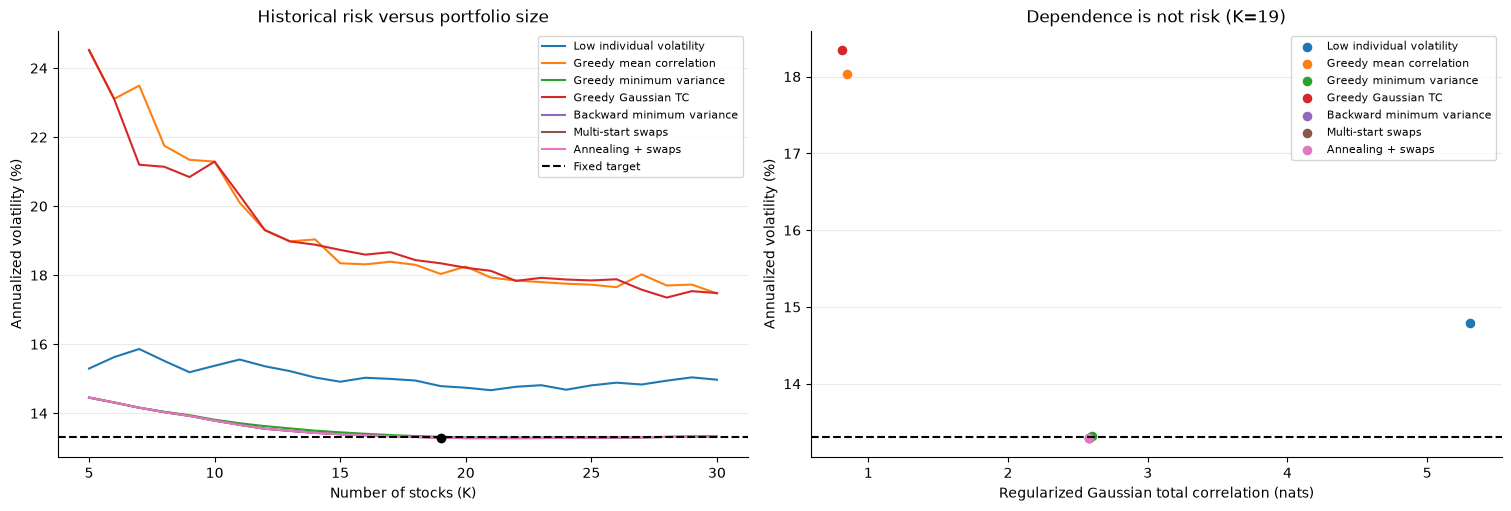

In [9]:
with plt.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
    for method, group in results.groupby("method", sort=False):
        group = group.sort_values("K")
        axes[0].plot(group["K"], 100 * group["annual_vol"], label=method, linewidth=1.5)
    axes[0].axhline(100 * VOL_LIMIT, color="black", linestyle="--", label="Fixed target")
    axes[0].scatter([int(winner["K"])], [100 * vol_check], color="black", zorder=5)
    axes[0].set(
        title="Historical risk versus portfolio size",
        xlabel="Number of stocks (K)", ylabel="Annualized volatility (%)",
    )
    axes[0].legend(fontsize=8, loc="best")
    at_k = results.loc[results["K"] == int(winner["K"])]
    for row in at_k.itertuples(index=False):
        axes[1].scatter(row.gaussian_tc_nats, 100 * row.annual_vol, s=35, label=row.method)
    axes[1].axhline(100 * VOL_LIMIT, color="black", linestyle="--")
    axes[1].set(
        title=f"Dependence is not risk (K={int(winner['K'])})",
        xlabel="Regularized Gaussian total correlation (nats)",
        ylabel="Annualized volatility (%)",
    )
    axes[1].legend(fontsize=8, loc="best")
    for ax in axes:
        ax.grid(axis="y", alpha=0.25)
    plt.show()


## 10. Interpretation, robustness and publication

- Selection and evaluation deliberately use the same historical sample. This is
  in-sample optimization; do not market the winner as a validated investment strategy.
- Filtering missingness over the whole sample is appropriate for this fixed exercise,
  but would use future availability in a historical trading backtest.
- The constituent history and price-adjustment methodology of the source file have
  not been audited. Survivorship bias and corporate-action effects remain possible.
- Report bridged date intervals and investigate them before calling every return
  a daily observation. Missing exchange sessions cannot be detected from this file alone.
- The weighted mean of log returns is the stipulated scoring convention; an actual
  rebalanced equal-weight portfolio has a different exact return aggregation.
- More seeds, more swaps or slower annealing may improve the reference. Recalibration
  must create a new version, not change an ongoing contest's threshold.
- Test TC regularization values such as `1e-10`, `1e-8` and `1e-6` in separate calibration
  runs. Near-collinear data and non-Gaussian tails can affect its interpretation.
- For a separate predictive experiment, choose stocks using only an earlier period
  and evaluate them on a later untouched period. Do not select the winner or tune
  its threshold on that later sample.
- The random-run dispersion above measures search stability, not future risk uncertainty.

Before publication, independently reproduce the official matrix and volatility,
freeze the configuration below, and give students a notebook without this instructor
solution. Keep the original Excel and exact cleaned returns alongside the manifest.


In [10]:
search_settings = {
    "seed": SEED, "low_vol_starts": N_LOW_VOL_STARTS,
    "random_forward_starts": N_RANDOM_STARTS,
    "random_swap_starts": N_RANDOM_SWAP_STARTS,
    "max_swap_rounds": MAX_SWAP_ROUNDS, "swap_variance_tolerance": SWAP_VAR_TOL,
    "annealing_restarts": SA_RESTARTS, "annealing_steps": SA_STEPS,
    "annealing_start_temperature_ratio": SA_START_TEMP_RATIO,
    "annealing_end_temperature_ratio": SA_END_TEMP_RATIO,
    "tc_ridge": TC_RIDGE,
}
challenge_config = {
    "version": "diversification_calibration_v3",
    "max_missing_fraction": MAX_MISSING_FRACTION,
    "min_k": MIN_K, "max_k": MAX_K,
    "annualization": ANNUALIZATION, "ddof": 1, "returns_type": "log",
    "threshold_relative_margin": THRESHOLD_MARGIN,
    "reference_vol": REFERENCE_VOL, "vol_limit": VOL_LIMIT,
    "vol_tolerance": VOL_TOL,
    "reference_k": int(reference["K"]), "reference_method": str(reference["method"]),
    "reference_tickers": reference["tickers"].split(","),
    "best_qualifying_k": int(winner["K"]), "best_qualifying_vol": vol_check,
    "best_qualifying_tickers": chosen,
    "source_sha256": source_sha256, "cleaned_returns_sha256": returns_sha256,
    "asset_order": tickers, "n_returns": len(returns),
    "first_return_date": str(returns.index.min().date()),
    "last_return_date": str(returns.index.max().date()),
    "bridged_intervals": bridged_intervals, "search_settings": search_settings,
    "software": {
        "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__
    },
}
manifest_id = hashlib.sha256(
    json.dumps(challenge_config, sort_keys=True).encode("utf-8")
).hexdigest()
print("Calibration manifest SHA256:", manifest_id)
print("Export enabled:", EXPORT_RESULTS)
if EXPORT_RESULTS:
    output_dir = Path("challenge_exports") / manifest_id[:16]
    output_dir.mkdir(parents=True, exist_ok=True)
    results.to_csv(output_dir / "all_methods.csv", index=False, float_format="%.17g")
    best_by_k.to_csv(output_dir / "best_by_k.csv", index=False, float_format="%.17g")
    search_runs.to_csv(output_dir / "search_runs.csv", index=False, float_format="%.17g")
    cleaning_audit.to_csv(output_dir / "cleaning_audit.csv", index_label="asset_id")
    (output_dir / "official_returns.csv").write_bytes(returns_csv.encode("utf-8"))
    (output_dir / "challenge_config.json").write_text(
        json.dumps(challenge_config, indent=2), encoding="utf-8"
    )
    print(f"Exported calibration to {output_dir.resolve()}")


Calibration manifest SHA256: c7791bc8110b489436138602a5a1dd543de438b731c03b0849c6de5c37d81062
Export enabled: False
